In [12]:
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
conn = sqlite3.connect('fencing.db')
query = "SELECT * FROM fencers"
fencers_df = pd.read_sql_query(query, conn)

fencers_df.head()

,id,fie_ID,name,dob,nationality,rank
0,1,21958,MASSIALAS Alexander,1994-04-20,USA,1
1,2,14397,MEINHARDT Gerek,1990-07-27,USA,2
2,3,41142,MARINI Tommaso,2000-04-17,ITA,3
3,4,22555,LEFORT Enzo,1991-09-29,FRA,4
4,5,37194,HAMZA Mohamed,2000-09-11,EGY,5


In [14]:
query = "SELECT * FROM comp"
comp_df = pd.read_sql_query(query, conn)

comp_df.head()

,id,event_type,comp_date,host_city
0,1,World Cup,2022-11-11,Bonn
1,2,World Cup,2022-12-09,Tokyo
2,3,World Cup,2023-01-12,Paris
3,4,Grand Prix,2023-02-11,Turin
4,5,World Cup,2023-02-23,Cairo


In [15]:
query = "SELECT * FROM points"
points_df = pd.read_sql_query(query, conn)

points_df.head()

,id,fie_id,comp_id,points_earned
0,1,21958,1,2.0
1,2,21958,2,14.0
2,3,21958,3,32.0
3,4,21958,4,21.0
4,5,21958,5,32.0


In [ ]:
Alexander_points = """
SELECT
    c.comp_date,
    p.points_earned

FROM comp c
JOIN points p ON c.id = p.comp_id
WHERE c.comp_date LIKE '2012%' 
    AND p.fie_ID = ( 
        SELECT fie_ID FROM fencers WHERE name = 'MASSIALAS Alexander' LIMIT 1);
"""
Alexander_points_df = pd.read_sql_query(Alexander_points, conn)

Alexander_points_df.head()

,comp_date,points_earned
0,2012-01-27,20.0
1,2012-02-17,14.0
2,2012-03-03,3.0
3,2012-03-16,8.0
4,2012-04-28,6.0


Text(0, 0.5, 'Points Earned')

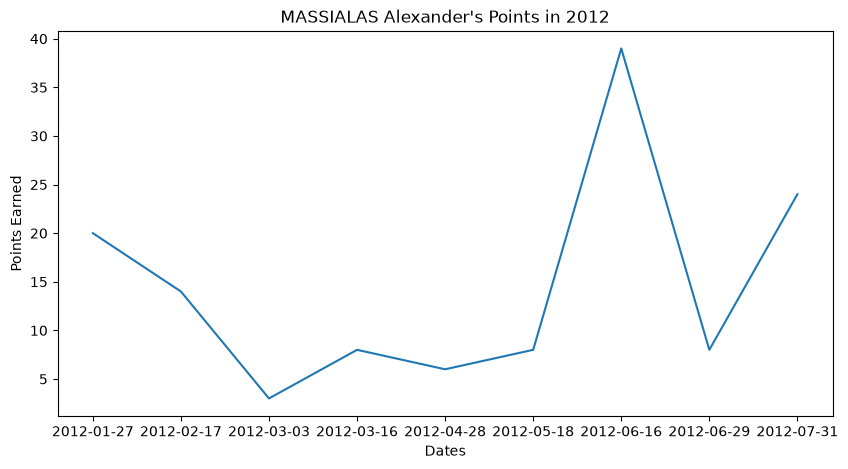

In [30]:
plt.figure(figsize=(10,5))
ax = sns.lineplot(data=Alexander_points_df, x='comp_date', y='points_earned')
ax.set_title("MASSIALAS Alexander's Points in 2012")
ax.set_xlabel('Dates')
ax.set_ylabel('Points Earned')